## Notebook setup

In [117]:
%run "set_up_X_y.ipynb"

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


C:\Users\NM2.ZVLKND36\AppData\Local\Temp\ipykernel_30108\3376826814.py:1: DtypeWarning: Columns (23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/covid_engineered_dataset.csv")


## Decision Tree Classifier

### Remove date col

In [119]:
X_train = X_train.drop(columns=["test_date", "corona_result", "age_60_and_above", "gender", "test_indication", "test_date_parsed"])
X_val = X_val.drop(columns=["test_date", "corona_result", "age_60_and_above", "gender", "test_indication", "test_date_parsed"])
X_test = X_test.drop(columns=["test_date", "corona_result", "age_60_and_above", "gender", "test_indication", "test_date_parsed"])

y_train_target = y_train["target"]
y_val_target = y_val["target"]
y_test_target = y_test["target"]

### Set up evaluation function


In [97]:
def evaluate_model(model, X, y, dataset_name):

    y_pred = model.predict(X)

    print(f"\n{dataset_name}")
    print(f"Accuracy:          {accuracy_score(y, y_pred):.2%}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y, y_pred):.2%}")
    print(f"Precision:         {precision_score(y, y_pred, zero_division=0):.2%}")
    print(f"Recall:            {recall_score(y, y_pred, zero_division=0):.2%}")
    print(f"F1 score:          {f1_score(y, y_pred, zero_division=0):.2%}")

    print("\nConfusion matrix:")
    print(confusion_matrix(y, y_pred))

### Baseline - Create and train, predict, and evaluate a simple DTC

In [98]:
# Create model
dtc_untuned = DecisionTreeClassifier(
    random_state=2
)

dtc_untuned.fit(X_train, y_train_target)

evaluate_model(
    dtc_untuned,
    X_train,
    y_train_target,
    "UNTUNED DTC: TRAIN"
)

evaluate_model(
    dtc_untuned,
    X_val,
    y_val_target,
    "UNTUNED DTC: VALIDATION"
)


UNTUNED DTC: TRAIN
Accuracy:          97.01%
Balanced accuracy: 78.41%
Precision:         81.05%
Recall:            57.58%
F1 score:          67.33%

Confusion matrix:
[[180620   1385]
 [  4363   5923]]

UNTUNED DTC: VALIDATION
Accuracy:          97.08%
Balanced accuracy: 78.51%
Precision:         82.38%
Recall:            57.71%
F1 score:          67.88%

Confusion matrix:
[[38729   272]
 [  932  1272]]


### Grid search

In [104]:
param_grid = {
    "max_depth": [2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [
        None,
        "balanced",
        {0: 1, 1: 2},
        {0: 1, 1: 3}
    ]
}

In [105]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2
)

dtc_search = DecisionTreeClassifier(
    random_state=2
)

grid = GridSearchCV(
    estimator=dtc_search,
    param_grid=param_grid,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "precision": "precision",
        "balanced_accuracy": "balanced_accuracy"
    },
    refit="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid.fit(X_train, y_train_target)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


,estimator,DecisionTreeC...andom_state=2)
,param_grid,"{'class_weight': [None, 'balanced', ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,"{'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,n_jobs,-1
,refit,'f1'
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,criterion,'gini'


In [106]:
print("Best parameters:")
print(grid.best_params_)

print(f"\nBest mean CV F1: {grid.best_score_:.3f}")

Best parameters:
{'class_weight': {0: 1, 1: 2}, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best mean CV F1: 0.674


In [107]:
dtc_tuned = grid.best_estimator_

evaluate_model(
    dtc_untuned,
    X_val,
    y_val_target,
    "UNTUNED DTC: VALIDATION"
)

evaluate_model(
    dtc_tuned,
    X_val,
    y_val_target,
    "TUNED DTC: VALIDATION"
)


UNTUNED DTC: VALIDATION
Accuracy:          97.08%
Balanced accuracy: 78.51%
Precision:         82.38%
Recall:            57.71%
F1 score:          67.88%

Confusion matrix:
[[38729   272]
 [  932  1272]]

TUNED DTC: VALIDATION
Accuracy:          96.92%
Balanced accuracy: 81.08%
Precision:         75.18%
Recall:            63.34%
F1 score:          68.75%

Confusion matrix:
[[38540   461]
 [  808  1396]]


In [108]:
evaluate_model(
    dtc_tuned,
    X_train,
    y_train_target,
    "TUNED DTC: TRAIN"
)

print("\nTree depth:", dtc_tuned.get_depth())
print("Number of leaves:", dtc_tuned.get_n_leaves())


TUNED DTC: TRAIN
Accuracy:          96.78%
Balanced accuracy: 80.53%
Precision:         73.38%
Recall:            62.35%
F1 score:          67.42%

Confusion matrix:
[[179679   2326]
 [  3873   6413]]

Tree depth: 4
Number of leaves: 16


### Investigate tree

In [110]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": dtc_tuned.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
9,Contact_with_confirmed,0.705413
15,Has_Biased_Symptom,0.208542
5,Fever,0.036215
16,Age_60,0.014320
18,Age_60_populated,0.013761
4,Cough,0.006853
14,Total_Symptoms,0.005264
12,Cough_and_Fever,0.003378
1,Age_60_Unknown,0.002603
8,Headache,0.002136


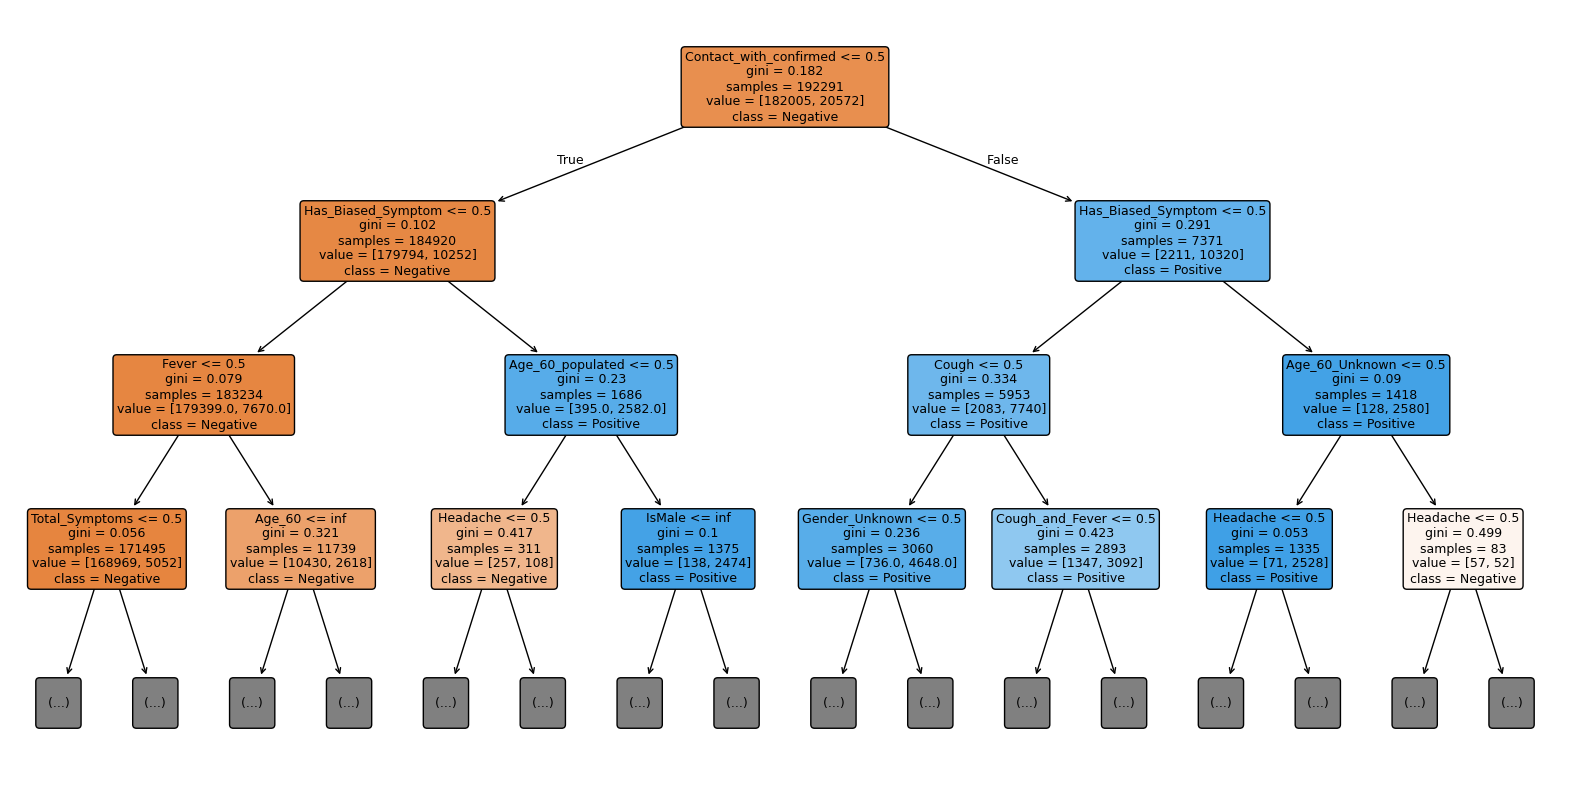

In [112]:
plt.figure(figsize=(20, 10))

plot_tree(
    dtc_tuned,
    feature_names=X_train.columns,
    class_names=["Negative", "Positive"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.show()

### Run on test set

In [114]:
evaluate_model(
    dtc_tuned,
    X_test,
    y_test_target,
    "FINAL TUNED DTC: TEST"
)


FINAL TUNED DTC: TEST
Accuracy:          96.69%
Balanced accuracy: 80.23%
Precision:         72.25%
Recall:            61.80%
F1 score:          66.62%

Confusion matrix:
[[38479   523]
 [  842  1362]]


### ROC AUC

In [120]:
# Probability of positive class (1)
y_prob_val = dtc_tuned.predict_proba(X_val)[:, 1]

# ROC-AUC score
roc_auc = roc_auc_score(y_val["target"], y_prob_val)

print(f"Validation ROC-AUC: {roc_auc:.3f}")

Validation ROC-AUC: 0.885


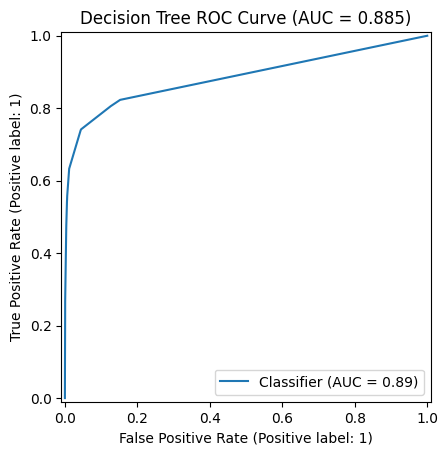

In [121]:
RocCurveDisplay.from_predictions(
    y_val["target"],
    y_prob_val
)

plt.title(f"Decision Tree ROC Curve (AUC = {roc_auc:.3f})")
plt.show()